In this file, we will train a Support Vector Machine (SVM) on the train dataset (which contains no anomalies) as a one-classification. This will give us the boundary of what is normal and anything that is outside this boundary will be labelled as an anomaly. We will work with the P1 dataset.

In [97]:
import numpy as np
import pandas as pd
train = pd.DataFrame(np.load("../data/data/train/P-1.npy"))
test = pd.DataFrame(np.load("../data/data/test/P-1.npy"))
train

,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
0,-0.523155,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,-0.688857,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,-0.554993,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,-0.531114,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,-0.589001,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2867,-0.691751,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2868,-0.704052,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2869,-0.725760,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2870,-0.689580,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Now it is important to note that SVM is for independent rows. Our data is time series where the rows are actually dependent on the rows around it. So we need to perform some feature engineering to get sliding windows to obtain some independence.

First we will eliminate collinearity in our columns.

In [98]:
#Let us store all the one hot encoded feature column names in a list
OHF = range(1,25)
crelation_matrix = train[OHF].corr().abs()
crelation_matrix

,1,2,3,4,5,6,7,8,9,10,...,15,16,17,18,19,20,21,22,23,24
1,1.000000,0.410546,0.842315,NaN,0.408575,0.023101,0.007019,NaN,0.140448,NaN,...,NaN,NaN,0.008506,0.008158,0.615935,NaN,0.160283,0.135184,NaN,NaN
2,0.410546,1.000000,0.013062,NaN,0.166085,0.192309,0.002882,NaN,0.002037,NaN,...,NaN,NaN,0.042106,0.042528,0.009171,NaN,0.383060,0.392263,NaN,NaN
3,0.842315,0.013062,1.000000,NaN,0.385865,0.063367,0.006322,NaN,0.075741,NaN,...,NaN,NaN,0.028653,0.028469,0.702095,NaN,0.023169,0.033299,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,0.408575,0.166085,0.385865,NaN,1.000000,0.866187,0.016140,NaN,0.024837,NaN,...,NaN,NaN,0.316140,0.313152,0.274993,NaN,0.382151,0.384500,NaN,NaN
6,0.023101,0.192309,0.063367,NaN,0.866187,1.000000,0.013980,NaN,0.009882,NaN,...,NaN,NaN,0.368406,0.364977,0.044489,NaN,0.428563,0.441507,NaN,NaN
7,0.007019,0.002882,0.006322,NaN,0.016140,0.013980,1.000000,NaN,0.000986,NaN,...,NaN,NaN,0.006322,0.006281,0.004438,NaN,0.007523,0.007347,NaN,NaN
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,0.140448,0.002037,0.075741,NaN,0.024837,0.009882,0.000986,NaN,1.000000,NaN,...,NaN,NaN,0.004468,0.004440,0.003137,NaN,0.131045,0.005193,NaN,NaN
10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [99]:
threshold = 0.95
const_cols = crelation_matrix.columns[crelation_matrix.isna().all()].tolist()

upper = crelation_matrix.where(np.triu(np.ones(crelation_matrix.shape, dtype=bool), k=1))
corr_cols = [col for col in upper.columns if (upper[col] > threshold).any()]

to_drop = const_cols + corr_cols

train = train.drop(columns = to_drop)
test = test.drop(columns = to_drop)
train

,0,1,2,3,5,6,7,9,11,13,17,19,21
0,-0.523155,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,-0.688857,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,-0.554993,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,-0.531114,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,-0.589001,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2867,-0.691751,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2868,-0.704052,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2869,-0.725760,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2870,-0.689580,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [100]:
train.columns

Index([0, 1, 2, 3, 5, 6, 7, 9, 11, 13, 17, 19, 21], dtype='int64')

Now, let us perform feature engineering. Let us write a function that will take in a dataframe and output a dataframe of the engineered features for a rolling window of size wind.

In [101]:
def feature_engineering(df , wind):
    features = pd.DataFrame()
    features["value"] = df[0]
    features["rmean"] = df[0].rolling(window=wind).mean()
    features["diff"] = df[0].diff()
    features["diff_std"] = df[0].diff().rolling(window=wind).std()
    features["rmin"]= df[0].rolling(window=wind).min()
    features["rmax"]= df[0].rolling(window=wind).max()
    features["rstd"]= df[0].rolling(window=wind).std()
    for i in df.columns:
        features[f"feature {i}"] = df[i].rolling(window=wind).sum()
        
    return features.iloc[wind:]

window=50
train_features = feature_engineering(train,window)
print("For a window of 50, our train data look like this: ")
train_features

For a window of 50, our train data look like this: 


,value,rmean,diff,diff_std,rmin,rmax,rstd,feature 0,feature 1,feature 2,feature 3,feature 5,feature 6,feature 7,feature 9,feature 11,feature 13,feature 17,feature 19,feature 21
50,-0.771346,-0.407815,0.002171,0.237831,-0.956585,0.753256,0.422444,-20.390737,4.0,2.0,2.0,12.0,9.0,0.0,0.0,0.0,0.0,2.0,1.0,4.0
51,-0.791606,-0.409870,-0.020260,0.236712,-0.956585,0.753256,0.424085,-20.493487,4.0,2.0,2.0,12.0,9.0,0.0,0.0,0.0,0.0,2.0,1.0,4.0
52,-0.752533,-0.413821,0.039074,0.235979,-0.956585,0.753256,0.426379,-20.691026,4.0,2.0,2.0,12.0,9.0,0.0,0.0,0.0,0.0,2.0,1.0,4.0
53,-0.777858,-0.418755,-0.025326,0.235963,-0.956585,0.753256,0.429183,-20.937770,4.0,2.0,2.0,12.0,9.0,0.0,0.0,0.0,0.0,2.0,1.0,4.0
54,-0.761939,-0.422214,0.015919,0.235856,-0.956585,0.753256,0.431275,-21.110708,4.0,2.0,2.0,12.0,9.0,0.0,0.0,0.0,0.0,2.0,1.0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2867,-0.691751,-0.327467,-0.518090,0.220147,-0.937771,0.570188,0.419644,-16.373371,2.0,0.0,2.0,8.0,6.0,0.0,0.0,0.0,0.0,2.0,1.0,3.0
2868,-0.704052,-0.326353,-0.012301,0.220123,-0.937771,0.570188,0.418545,-16.317655,2.0,0.0,2.0,8.0,6.0,0.0,0.0,0.0,0.0,2.0,1.0,3.0
2869,-0.725760,-0.326252,-0.021708,0.220109,-0.937771,0.570188,0.418446,-16.312590,2.0,0.0,2.0,8.0,6.0,0.0,0.0,0.0,0.0,2.0,1.0,3.0
2870,-0.689580,-0.325051,0.036179,0.220150,-0.937771,0.570188,0.417290,-16.252532,2.0,0.0,2.0,8.0,6.0,0.0,0.0,0.0,0.0,2.0,1.0,3.0


In [102]:
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit

In [103]:
model = Pipeline(steps=[
                        ("Scaler", StandardScaler()),
                        ("SVM" , OneClassSVM(nu=0.01))
                        ])

In [104]:
gamma = [0.1 , 0.01, 0.001]
nu = [0.01, 0.03, 0.05, 0.07, 0.1]
for w in [5,10,15,20]:
    train_features = feature_engineering(train,w)
    tscv = TimeSeriesSplit(n_splits=15, gap=w)
    cols = pd.MultiIndex.from_product([gamma, nu], names=["gamma", "nu"])
    results = pd.DataFrame(columns=cols, index=range(15))
    results.index.name = "Split"

    for g in gamma:
        for n in nu:
            model.set_params(SVM__gamma=g, SVM__nu=n)
            for i, (train_index, test_index) in enumerate(tscv.split(train_features)):
                X_train = train_features.iloc[train_index]
                X_test = train_features.iloc[test_index]
                model.fit(X_train)
                fpr = (model.predict(X_test)==-1).mean()
                results.loc[i,(g,n)]=fpr
    print(f"results for window length {w}")
    print(results)

results for window length 5
gamma     0.100                                             0.010            \
nu         0.01      0.03      0.05      0.07      0.10      0.01      0.03   
Split                                                                         
0      0.402235  0.402235  0.402235  0.402235  0.402235  0.100559  0.111732   
1       0.22905   0.22905   0.22905   0.22905   0.22905  0.022346  0.022346   
2      0.173184  0.173184  0.173184  0.173184  0.184358   0.03352  0.050279   
3      0.167598  0.167598  0.167598  0.167598  0.189944  0.022346  0.022346   
4      0.128492  0.128492  0.128492  0.128492  0.145251  0.022346  0.027933   
5      0.083799  0.083799  0.083799  0.089385  0.100559  0.005587  0.005587   
6      0.111732  0.111732  0.111732  0.122905  0.128492  0.005587  0.022346   
7      0.128492  0.128492  0.128492  0.122905  0.134078   0.01676   0.03352   
8      0.067039  0.067039  0.072626  0.067039  0.078212  0.011173  0.027933   
9      0.094972  0.10055

Let us try to perform the analysis only for telemetary.

In [105]:
gamma = [0.1 , 0.01, 0.001]
nu = [0.01, 0.03, 0.05, 0.07, 0.1]
for w in [5,10,15,20]:
    train_features = feature_engineering(train,w)
    train_features = train_features.iloc[:,:7]
    tscv = TimeSeriesSplit(n_splits=15, gap=w)
    cols = pd.MultiIndex.from_product([gamma, nu], names=["gamma", "nu"])
    results = pd.DataFrame(columns=cols, index=range(15))
    results.index.name = "Split"

    for g in gamma:
        for n in nu:
            model.set_params(SVM__gamma=g, SVM__nu=n)
            for i, (train_index, test_index) in enumerate(tscv.split(train_features)):
                X_train = train_features.iloc[train_index]
                X_test = train_features.iloc[test_index]
                model.fit(X_train)
                fpr = (model.predict(X_test)==-1).mean()
                results.loc[i,(g,n)]=fpr
    print(f"results for window length {w}")
    print(results)

results for window length 5
gamma     0.100                                             0.010            \
nu         0.01      0.03      0.05      0.07      0.10      0.01      0.03   
Split                                                                         
0      0.156425  0.156425  0.156425  0.184358  0.184358  0.044693  0.044693   
1      0.078212  0.078212  0.145251  0.162011  0.167598  0.011173   0.01676   
2      0.078212  0.089385  0.100559  0.111732  0.134078  0.039106  0.083799   
3       0.03352  0.039106  0.050279  0.072626  0.100559       0.0  0.005587   
4      0.150838  0.145251  0.145251  0.156425  0.184358  0.005587  0.011173   
5           0.0  0.005587   0.01676  0.027933  0.027933       0.0  0.005587   
6           0.0   0.01676  0.061453  0.100559  0.134078  0.005587  0.055866   
7      0.039106  0.061453  0.078212  0.094972  0.117318  0.005587  0.027933   
8      0.027933  0.039106  0.050279  0.067039  0.083799  0.011173   0.03352   
9       0.03352  0.04469

### Choosing the final settings

Before touching the test set, we pick one configuration using only the training-set validation results above. For every window length, feature set (all features vs. telemetry only), gamma and nu, we compute the mean validation false-positive rate across the 15 splits. We take the configuration with the lowest mean FPR. If there is a tie, we will pick the smaller window.

We also use the validation folds to choose `min_flags`, the minimum number of flagged rows an alert must contain. The training data has no anomalies, so every validation flag is a false alarm. We group these flags the same way we will group the test flags (flags at most `window` rows apart form one cluster) and record the size of the largest cluster. For the selected configuration, `min_flags` is one more than that size, so none of the false clusters seen in validation would have raised an alert.

In [106]:
cv_rows = []
for w in [5, 10, 15, 20]:
    for telemetry_only in [False, True]:
        feats = feature_engineering(train, w)
        if telemetry_only:
            feats = feats.iloc[:, :7]
        tscv = TimeSeriesSplit(n_splits=15, gap=w)
        for g in [0.1, 0.01, 0.001]:
            for n in [0.01, 0.03, 0.05, 0.07, 0.1]:
                model.set_params(SVM__gamma=g, SVM__nu=n)
                fprs = []
                val_flagged = []   # original row numbers of every flagged validation row
                for train_index, val_index in tscv.split(feats):
                    model.fit(feats.iloc[train_index])
                    val_pred = model.predict(feats.iloc[val_index]) == -1
                    fprs.append(val_pred.mean())
                    val_flagged.extend(feats.index[val_index][val_pred])

                # The training data has no anomalies, so every flag is a false alarm.
                # Group the flags exactly as we will on the test set (flags at most w rows
                # apart are merged) and record the size of the largest false cluster.
                val_flagged = np.sort(np.asarray(val_flagged))
                breaks = np.where(np.diff(val_flagged) > w)[0]
                cluster_sizes = np.diff(np.r_[0, breaks + 1, len(val_flagged)])
                max_false_cluster = int(cluster_sizes.max()) if len(val_flagged) else 0

                cv_rows.append({"window": w, "telemetry_only": telemetry_only,
                                "gamma": g, "nu": n, "mean_val_FPR": np.mean(fprs),
                                "max_false_cluster": max_false_cluster})

cv_summary = (pd.DataFrame(cv_rows)
              .sort_values(["mean_val_FPR", "window"])
              .reset_index(drop=True))
display(cv_summary.head(10))

best = cv_summary.iloc[0]
best_window = int(best["window"])
best_gamma = float(best["gamma"])
best_nu = float(best["nu"])
telemetry_only = bool(best["telemetry_only"])
# An alert must contain more flags than any false cluster seen during validation
best_min_flags = int(best["max_false_cluster"]) + 1
print(f"Selected: window={best_window}, gamma={best_gamma}, nu={best_nu}, "
      f"telemetry_only={telemetry_only}, min_flags={best_min_flags}")

,window,telemetry_only,gamma,nu,mean_val_FPR,max_false_cluster
0,10,True,0.001,0.01,0.017978,7
1,10,True,0.010,0.01,0.019101,7
2,5,True,0.001,0.01,0.019367,12
3,10,False,0.001,0.01,0.019850,10
4,5,False,0.001,0.01,0.020484,9
5,5,True,0.010,0.01,0.020484,12
6,15,True,0.001,0.01,0.026592,14
7,15,True,0.010,0.01,0.029588,16
8,5,False,0.010,0.01,0.030168,11
9,20,True,0.001,0.01,0.032959,19


Selected: window=10, gamma=0.001, nu=0.01, telemetry_only=True, min_flags=8


### Fit on the full training set and predict on the test set

We refit the selected configuration on all training rows. Then we build the test features with the same window and columns, and predict each test row (-1 = anomaly).

The true label of a test row is 1 if its index falls inside one of the expert-labelled anomaly intervals in `labeled_anomalies.csv` (inclusive endpoints), and 0 otherwise.

In [107]:
import ast

labels = pd.read_csv("../data/data/labeled_anomalies.csv")
labeled_intervals = ast.literal_eval(
    labels.loc[labels["chan_id"] == "P-1", "anomaly_sequences"].iloc[0])
print("Labelled anomaly intervals:", sorted(labeled_intervals))

train_feats = feature_engineering(train, best_window)
test_feats = feature_engineering(test, best_window)
if telemetry_only:
    train_feats = train_feats.iloc[:, :7]
    test_feats = test_feats.iloc[:, :7]

model.set_params(SVM__gamma=best_gamma, SVM__nu=best_nu)
model.fit(train_feats)

# 1 = predicted anomaly, 0 = predicted normal. We  need to do this since SVM predicts 1(normal) or -1(outlier)
y_pred = (model.predict(test_feats) == -1).astype(int)

# True point labels, aligned with the test feature rows (which keep their original index)
y_true = np.zeros(len(test), dtype=int)
for start, end in labeled_intervals:
    y_true[start:end + 1] = 1
y_true = y_true[test_feats.index]

print("Test rows evaluated:", len(y_true))
print("True anomalous rows:", y_true.sum())
print("Predicted anomalous rows:", y_pred.sum())

Labelled anomaly intervals: [[2149, 2349], [3539, 3779], [4536, 4844]]
Test rows evaluated: 8495
True anomalous rows: 751
Predicted anomalous rows: 301


### Point-level metrics

Each test row counts as one prediction:

- **Precision** = TP / (TP + FP): of the rows we flagged, how many were really anomalous.
- **Recall** = TP / (TP + FN): of the truly anomalous rows, how many we flagged.
- **False positive rate** = FP / (FP + TN): of the normal rows, how many we wrongly flagged.
- **F1** = the harmonic mean of precision and recall.

In [108]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

point_metrics = pd.Series({
    "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    "precision": precision_score(y_true, y_pred, zero_division=0),
    "recall": recall_score(y_true, y_pred, zero_division=0),
    "false positive rate": fp / (fp + tn),
    "F1": f1_score(y_true, y_pred, zero_division=0),
}, name="point-level", dtype=object)
point_metrics.to_frame()

,point-level
TP,193
FP,108
FN,558
TN,7636
precision,0.641196
recall,0.256991
false positive rate,0.013946
F1,0.36692


### Event-level metrics

Point-level recall is low whenever the model flags only part of a long anomaly. The original paper instead scores **events**: a labelled interval counts as detected if at least one alert overlaps it, and an alert that overlaps no labelled interval is a false positive. This uses `evaluate_event_detection()` from `detection.py`, the same scoring as the other notebooks.

Flagged rows are grouped into alert intervals. Flags separated by no more than `best_window` steps are merged into one alert, because every feature row summarises the previous `best_window` readings. Event-level FPR is not defined, since there are no "true negative events".

In [109]:
import sys
sys.path.insert(0, "..")
from detection import evaluate_event_detection

#This is a fucntion to convert a list of timestamps to intervals
def flags_to_intervals(indices, max_gap=1, min_flags=1):
    # Group sorted indices into inclusive (start, end) intervals.
    # Flags at most max_gap apart are merged into one interval.
    # Intervals containing fewer than min_flags flagged rows are dropped.
    if len(indices) == 0:
        return []
    indices = np.sort(np.asarray(indices))
    breaks = np.where(np.diff(indices) > max_gap)[0]
    starts = np.r_[indices[0], indices[breaks + 1]]
    ends = np.r_[indices[breaks], indices[-1]]

    # Number of flagged rows in each interval; keep only the large ones
    counts = np.diff(np.r_[0, breaks + 1, len(indices)])
    keep = counts >= min_flags

    return [(int(s), int(e)) for s, e in zip(starts[keep], ends[keep])]

#First let us keep track of the anomalous timestamps
flagged_indices = test_feats.index.to_numpy()[y_pred == 1]

#Now let us use the function to convert timestamps into intervals,
#keeping only intervals with at least min_flags flagged rows (chosen during cross-validation)
min_flags = best_min_flags
alert_intervals = flags_to_intervals(flagged_indices, max_gap=best_window, min_flags=min_flags)

event_eval = evaluate_event_detection(alert_intervals, labeled_intervals)

print("Number of alert intervals:", len(alert_intervals))
for interval, detected in zip(labeled_intervals, event_eval["detected_event_mask"]):
    print(f"Labelled event {interval}: {'Detected' if detected else 'Missed'}")

event_metrics = pd.Series({
    "TP": event_eval["TP"], "FP": event_eval["FP"], "FN": event_eval["FN"],
    "precision": event_eval["precision"], "recall": event_eval["recall"],
    "F1": event_eval["f1"],
}, name="event-level", dtype=object)
event_metrics.to_frame()

Number of alert intervals: 6
Labelled event [2149, 2349]: Detected
Labelled event [4536, 4844]: Detected
Labelled event [3539, 3779]: Detected


,event-level
TP,3
FP,2
FN,0
precision,0.6
recall,1.0
F1,0.75


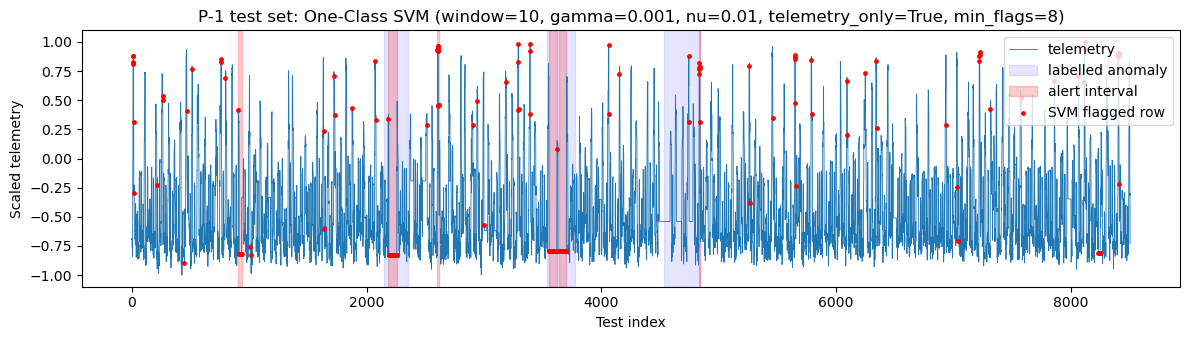

In [110]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(test.index, test[0], lw=0.6, label="telemetry")
for k, (s, e) in enumerate(labeled_intervals):
    ax.axvspan(s, e, color="blue", alpha=0.1, label="labelled anomaly" if k == 0 else None)
for k, (s, e) in enumerate(alert_intervals):
    ax.axvspan(s, e, color="red", alpha=0.2, label="alert interval" if k == 0 else None)
ax.scatter(flagged_indices, test.loc[flagged_indices, 0], s=6, color="red",
           label="SVM flagged row", zorder=3)
ax.set_title(f"P-1 test set: One-Class SVM (window={best_window}, gamma={best_gamma}, nu={best_nu}, "
             f"telemetry_only={telemetry_only}, min_flags={min_flags})")
ax.set_xlabel("Test index")
ax.set_ylabel("Scaled telemetry")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()